# Análisis exploratorio — cadena de puntos cuánticos

Este notebook reproduce el análisis inicial de los datos exportados desde COMSOL:
lectura de los `.txt`, separación de autovalores por modo, gráficas de energía
y análisis del momento dipolar inducido.

> **Datos:** `../data/` · **Figuras:** `../figures/`
> Los outputs fueron removidos para mantener el repositorio liviano.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt






####  Lectura y dividir valores propios

In [ ]:
def organizar_valores_propios(df):
    df = df.copy()
    
    # 1. ORDENAR LOS DATOS: Primero por 'X' y luego por 'Valor_propio'
    df = df.sort_values(by=['X', 'Valor_propio']).reset_index(drop=True)
    
    # 2. Asignar el Modo. Ahora siempre el Modo 0 serÃƒÆ’Ã‚Â¡ el estado fundamental, 
    # el Modo 1 el primer estado excitado, etc.
    df['Modo'] = df.groupby('X').cumcount()
    
    # 3. Pivotar la tabla
    df = df.pivot(index='X',
                  columns='Modo',
                  values='Valor_propio')
    
    # 4. Renombrar columnas
    df.columns = [f'VP_{i+1}' for i in df.columns]
    
    return df.reset_index()

In [ ]:
DATA = "../data/"   # exportaciones de COMSOL

#----------------------CASO UNIFORME  E vs xi------------------------
# 1. Saltamos 8 filas (esto elimina hasta el encabezado "% X Valor propio")
# Luego definimos las columnas manualmente como 'X' y 'Valor_propio'
df1 = pd.read_csv(DATA + 'caso1.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

df1F = pd.read_csv(DATA + 'c1_F.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

#2.2

df2_2 = pd.read_csv(DATA + 'caso2_2.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

df2_2F = pd.read_csv(DATA + 'c2_2_F.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')


#3

df3 = pd.read_csv(DATA + 'caso3.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

df3F = pd.read_csv(DATA + 'c3_F.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

#--------------------CASO NO UNIFORME E vs R5--------------------

# sin impureza
df_R5sind0 = pd.read_csv(DATA + 'EvsR5sind0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5sind10 = pd.read_csv(DATA + 'EvsR5sind10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5sind_10 = pd.read_csv(DATA + 'EvsR5sind-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

# con impureza xi=0
df_R5xi0d0 = pd.read_csv(DATA + 'EvsR5xi=0d0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xi0d10 = pd.read_csv(DATA + 'EvsR5xi=0d10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xi0d_10 = pd.read_csv(DATA + 'EvsR5xi=0d-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

# con impureza x=R1
df_R5xiR1d0 = pd.read_csv(DATA + 'EvsR5xi=R1d0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xiR1d10 = pd.read_csv(DATA + 'EvsR5xi=R1d10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xiR1d_10 = pd.read_csv(DATA + 'EvsR5xi=R1d-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

# con impureza x=R5
df_R5xiR5d0 = pd.read_csv(DATA + 'EvsR5xi=R5d0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xiR5d10 = pd.read_csv(DATA + 'EvsR5xi=R5d10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_R5xiR5d_10 = pd.read_csv(DATA + 'EvsR5xi=R5d-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')


#--------------------CASO NO UNIFORME E vs xi=R5--------------------

# Con Ri=10
df_xiR5_10d0 = pd.read_csv(DATA + 'EvsxiR5=10d0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_xiR5_10d10 = pd.read_csv(DATA + 'EvsxiR5=10d10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_xiR5_10d_10 = pd.read_csv(DATA + 'EvsxiR5=10d-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

# Con Ri=50
df_xiR5_50d0 = pd.read_csv(DATA + 'EvsxiR5=50d0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_xiR5_50d10 = pd.read_csv(DATA + 'EvsxiR5=50d10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_xiR5_50d_10 = pd.read_csv(DATA + 'EvsxiR5=50d-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')




# -------------------- CASO AEvsF --------------------

# Para R = 10
df_AEvsF_R10_d_0 = pd.read_csv(DATA + 'AEvsF_R10_d_0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_AEvsF_R10_d_10 = pd.read_csv(DATA + 'AEvsF_R10_d_10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_AEvsF_R10_d_menos10 = pd.read_csv(DATA + 'AEvsF_R10_d_-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

# Para R = 50
df_AEvsF_R50_d_0 = pd.read_csv(DATA + 'AEvsF_R50_d_0.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_AEvsF_R50_d_10 = pd.read_csv(DATA + 'AEvsF_R50_d_10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')
df_AEvsF_R50_d_menos10 = pd.read_csv(DATA + 'AEvsF_R50_d_-10.txt', skiprows=8, sep=r'\s+', names=['X', 'Valor_propio'], engine='python')

In [ ]:
df1o  = organizar_valores_propios(df1)
df1Fo = organizar_valores_propios(df1F)
df2_2o  = organizar_valores_propios(df2_2)
df2_2Fo = organizar_valores_propios(df2_2F)
df3o  = organizar_valores_propios(df3)
df3Fo = organizar_valores_propios(df3F)


# Aplicar la función de organización a los nuevos DataFrames
df_R5sind0o = organizar_valores_propios(df_R5sind0)
df_R5sind10o = organizar_valores_propios(df_R5sind10)
df_R5sind_10o = organizar_valores_propios(df_R5sind_10)

df_R5xi0d0o = organizar_valores_propios(df_R5xi0d0)
df_R5xi0d10o = organizar_valores_propios(df_R5xi0d10)
df_R5xi0d_10o = organizar_valores_propios(df_R5xi0d_10)

df_R5xiR1d0o = organizar_valores_propios(df_R5xiR1d0)
df_R5xiR1d10o = organizar_valores_propios(df_R5xiR1d10)
df_R5xiR1d_10o = organizar_valores_propios(df_R5xiR1d_10)

df_R5xiR5d0o = organizar_valores_propios(df_R5xiR5d0)
df_R5xiR5d10o = organizar_valores_propios(df_R5xiR5d10)
df_R5xiR5d_10o = organizar_valores_propios(df_R5xiR5d_10)


# Aplicar la función de organización
df_xiR5_10d0o = organizar_valores_propios(df_xiR5_10d0)
df_xiR5_10d10o = organizar_valores_propios(df_xiR5_10d10)
df_xiR5_10d_10o = organizar_valores_propios(df_xiR5_10d_10)

df_xiR5_50d0o = organizar_valores_propios(df_xiR5_50d0)
df_xiR5_50d10o = organizar_valores_propios(df_xiR5_50d10)
df_xiR5_50d_10o = organizar_valores_propios(df_xiR5_50d_10)



# Aplicar la función de organización

# Para R = 10
df_AEvsF_R10_d_0o = organizar_valores_propios(df_AEvsF_R10_d_0)
df_AEvsF_R10_d_10o = organizar_valores_propios(df_AEvsF_R10_d_10)
df_AEvsF_R10_d_menos10o = organizar_valores_propios(df_AEvsF_R10_d_menos10)

# Para R = 50
df_AEvsF_R50_d_0o = organizar_valores_propios(df_AEvsF_R50_d_0)
df_AEvsF_R50_d_10o = organizar_valores_propios(df_AEvsF_R50_d_10)
df_AEvsF_R50_d_menos10o = organizar_valores_propios(df_AEvsF_R50_d_menos10)


# CASO UNIFORME 

## Comparacion E VS xi

In [ ]:
# ==========================================
# COMPARACIÓN CASOS UNIFORMES: d=0, d=10 y d=-10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df3o, "titulo": "d = -10 nm", "xlim": (-130, 130), "ylim": (-0.022, 0.005)},
    {"df": df1o, "titulo": "d = 0 nm", "xlim": (-150, 150), "ylim": (-0.022, 0.005)},
    {"df": df2_2o, "titulo": "d = 10 nm", "xlim": (-180, 180), "ylim": (-0.022, 0.005)},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Número de curvas (lambda)
n_col = df1o.shape[1] - 1  # restamos la columna 'X'
k_cols = df1o.columns[1:] # tomamos hasta las primeras 8 curvas

# Usamos la misma paleta cividis que en la celda 13
colors = plt.cm.cividis(np.linspace(0.15, 0.95, len(k_cols)))

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    xi_nm = df_actual["X"] * 1e9
    
    # Graficar cada una de las curvas
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            xi_nm,
            df_actual[col],
            color=colors[i - 1],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"$\\lambda$ = {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de límites y etiquetas de cada gráfica
    ax.set_xlim(caso["xlim"])
    ax.set_ylim(caso["ylim"])
    ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)
    
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    # Encontrar el valor mínimo global de todas las curvas en este subplot
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    # Texto en negrita, justo debajo del primer valor del eje Y (-0.020)
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - 0.0012,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Comparativa de Energía vs Xi para diferentes d", fontsize=15, weight='semibold', y=0.98)

plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsXiUniforme.png', dpi=300, bbox_inches='tight')
plt.show()

## CASO 1  d=0nm

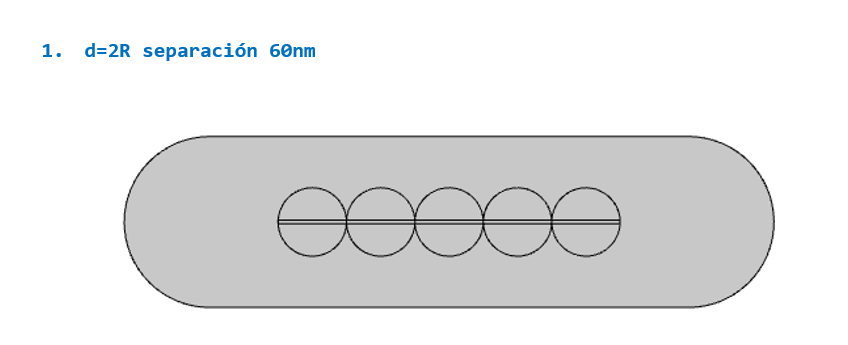

### E vs xi

In [ ]:
plt.figure(figsize=(10, 6))
xi_nm = df1["X"] * 1e9
plt.scatter(xi_nm, df1["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia  vs Xi')
plt.xlabel('Xi (nm)')
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df1o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] * 1e9
k = df_actual.columns[1:9]            # Selecciona las columnas, saltando 'X'

plt.figure(figsize=(10, 6), dpi=150)
ax = plt.gca()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

colors = plt.cm.cividis(np.linspace(0.15, 0.95, len(k)))

for i, col in enumerate(k, start=1):
    ax.plot(
        xi_nm,
        df_actual[col],
        color=colors[i - 1],
        lw=2.8,
        alpha=0.95,
        solid_capstyle='round',
        label=f"$\\lambda$ = {i}"
    )

ax.set_ylim(-0.022, 0.0035)
ax.set_xlim(-150, 150)
ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
ax.set_title("Energía vs Xi d=0", fontsize=14, pad=20)
ax.grid(False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

ax.tick_params(axis='both', which='both', length=0, colors='#333333')

ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.01, 1.0),
    frameon=False,
    title='Valores propios',
    title_fontsize=10,
    fontsize=8,
    handlelength=2.0
)

plt.tight_layout()
plt.savefig('../figures/c_u_Evsxi_d0.png', dpi=300, bbox_inches='tight')
plt.show()

### E vs F , xi=2d

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df1F["X"],df1F["Valor_propio"], s=1, alpha=0.5) # s es el tamaÃƒÆ’Ã‚Â±o del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df1Fo                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(10,6))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5,
        label=f"Valor propio {i}"
    )

plt.xlabel("F (kV/cm)")
plt.xlim(-2, 4)
plt.ylabel("Energgia (ev)")
plt.title("Energia vs F")
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Curvas"
)

plt.tight_layout()
plt.show()

### Analisi momento

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df1Fo                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:3]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(10, 6), dpi=150)
ax = plt.gca()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

colors = plt.cm.cividis(np.linspace(0.15, 0.95, len(k)))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    ax.plot(
        xi_nm,
        df_actual[col],
        color=colors[i - 1],
        lw=2.8,
        alpha=0.95,
        solid_capstyle='round',
        label=f"Valor propio {i}"
    )

ax.set_xlabel(r"$\mathbf{F (kV/cm)}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
ax.set_title("Energía vs F", fontsize=14, pad=20)
ax.grid(False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

ax.tick_params(axis='both', which='both', length=0, colors='#333333')

ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.01, 1.0),
    frameon=False,
    title='Curvas',
    title_fontsize=10,
    fontsize=8,
    handlelength=2.0
)

plt.tight_layout()
plt.show()

In [ ]:
# --- Análisis: ajuste de dos rectas para el primer valor propio (debajo de la celda 25)
# Define los límites a considerar: ajusta F_min y F_max según necesites
F_min, F_max = -2.0, 4.0
# Usamos el DataFrame con valores en función de F (df_actual) y la primera columna de valores propios
df = df_actual.copy()

F = np.array(df['X'])
col = df.columns[1]  # primer valor propio
E = np.array(df[col])
# Filtrar por los límites deseados
mask = (F >= F_min) & (F <= F_max)
Fm = F[mask]
Em = E[mask]
if len(Fm) < 3:
    print('No hay suficientes puntos en el rango seleccionado. Ajusta F_min/F_max')
else:
    # Detectar punto de quiebre local (máximo dentro del intervalo seleccionado)
    idx_local = np.argmax(Em)
    F_quiebre = Fm[idx_local]
    E_quiebre = Em[idx_local]

    # Función para calcular pendiente forzando la unión en (x0,y0)
    def pendiente_forzada(x, y, x0, y0):
        return np.sum((x - x0) * (y - y0)) / np.sum((x - x0)**2)

    # Separar en los dos tramos alrededor del punto de quiebre
    F1, E1 = Fm[:idx_local+1], Em[:idx_local+1]
    F2, E2 = Fm[idx_local:], Em[idx_local:]

    m1 = pendiente_forzada(F1, E1, F_quiebre, E_quiebre)
    m2 = pendiente_forzada(F2, E2, F_quiebre, E_quiebre)

    # Interceptos (forma y = m*x + b)
    b1 = E_quiebre - m1 * F_quiebre
    b2 = E_quiebre - m2 * F_quiebre

    # Imprimir resultados (pendientes y ecuaciones)
    print(f'Columna analizada: {col}')
    print(f'Recta 1: E = {m1:.6e} * F + {b1:.6e}    (pendiente = {m1:.6e})')
    print(f'Recta 2: E = {m2:.6e} * F + {b2:.6e}    (pendiente = {m2:.6e})')

    # Graficar: datos completos en gris, datos usados en naranja, y rectas ajustadas
    plt.figure(figsize=(10,6))
    plt.scatter(F, E, s=10, c='lightgray', label='Datos (completos)')
    plt.scatter(Fm, Em, s=30, c='orange', label='Datos usados')
    # Rectas ajustadas (se dibujan en el rango usado para cada tramo)
    plt.plot(F1, m1 * (F1 - F_quiebre) + E_quiebre, 'b-', lw=3, label=f'Tramo 1 (m={m1:.3e})')
    plt.plot(F2, m2 * (F2 - F_quiebre) + E_quiebre, 'r-', lw=3, label=f'Tramo 2 (m={m2:.3e})')
    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Energia (eV)')
    plt.title('Ajuste por dos rectas - primer valor propio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
# Celda 28: Graficar las pendientes (m1 y m2) vs F con la línea vertical de separación
try:
    # Asegurarse de que las variables m1, m2, F1, F2, F_quiebre estén definidas
    _ = (m1, m2, F1, F2, F_quiebre)
except Exception:
    print('Faltan variables necesarias (m1,m2,F1,F2,F_quiebre). Ejecuta la celda de análisis anterior.')
else:
    # Construir arrays de pendientes a lo largo de F para visualización
    # Usamos df_actual['X'] como eje F completo
    F_all = np.array(df_actual['X'])

    # Crear arrays de pendiente con NaN inicialmente
    pend1 = np.full_like(F_all, np.nan, dtype=float)
    pend2 = np.full_like(F_all, np.nan, dtype=float)

    # Rellenar pend1 en el rango de F1 y pend2 en el rango de F2
    # Para ello, identificamos índices en F_all que pertenecen a F1 y F2
    idx1 = np.isin(F_all, F1)
    idx2 = np.isin(F_all, F2)

    pend1[idx1] = m1
    pend2[idx2] = m2

    plt.figure(figsize=(10,6))
    plt.plot(F_all, pend1, 'b-', lw=3, label=f'Pendiente tramo 1 = {m1:.4e}')
    plt.plot(F_all, pend2, 'r-', lw=3, label=f'Pendiente tramo 2 = {m2:.4e}')

    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')

    plt.xlabel('F (kV/cm)')
    plt.ylabel('Pendiente dE/dF (eV / (kV/cm))')
    plt.title('Pendientes por tramo vs F (primer valor propio)')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Unidades

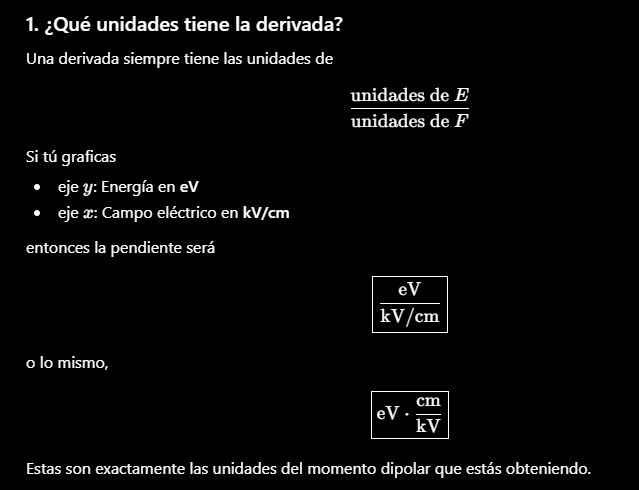

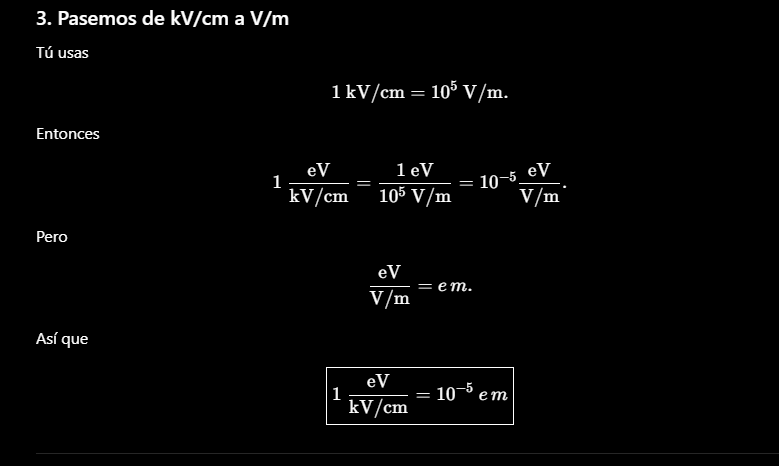


## Caso 2_2 d=10 nm

### E vs xi

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df2_2["X"]*1e9,df2_2["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs Xi')
plt.xlabel('Xi (nm)')
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df2_2o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] * 1e9
k = df_actual.columns[1:9]            # Selecciona las columnas, saltando X

plt.figure(figsize=(10, 6), dpi=150)
ax = plt.gca()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

colors = plt.cm.viridis(np.linspace(0.15, 0.95, len(k)))

for i, col in enumerate(k, start=1):
    ax.plot(
        xi_nm,
        df_actual[col],
        color=colors[i - 1],
        lw=2.8,
        alpha=0.95,
        solid_capstyle='round',
        label=f"$\\lambda$ = {i}"
    )
ax.set_ylim(-0.022, 0.005)
ax.set_xlim(-180, 180)
ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
ax.set_title("Energía vs Xi d =10 ", fontsize=14, pad=20)
ax.grid(False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

ax.tick_params(axis='both', which='both', length=0, colors='#333333')

ax.legend(
    loc='center left',
    bbox_to_anchor=(1.01, 0.7),
    frameon=False,
    title='Valores propios',
    title_fontsize=10,
    fontsize=9,
    handlelength=2.0
)

plt.tight_layout()
plt.savefig('../figures/c_u_Evsxi_d10.png', dpi=300, bbox_inches='tight')
plt.show()

### E vs F , xi=2d

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df2_2F["X"],df2_2F["Valor_propio"], s=1, alpha=0.5) # s es el tamaÃƒÆ’Ã‚Â±o del punto
plt.title('Energia vs F')

plt.xlabel('F (kV/cm)')
plt.ylabel('Energia (eV)')
plt.grid(True)
plt.show()

### Analisi momento

IA AQUI!!, LA GRAFICA QUE HAY ABAJO LA VAMOS A EXPORTAR . d=10

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df2_2Fo                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(10,6))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5,
        label=f"Valor propio {i}"
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energgia (ev)")
plt.title("Energia vs F")
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Curvas"
)

plt.tight_layout()
plt.show()

In [ ]:
# --- Análisis: ajuste de dos rectas para el primer valor propio (debajo de la celda 25)
# Define los límites a considerar: ajusta F_min y F_max según necesites
F_min, F_max = -1.1, 2
# Usamos el DataFrame con valores en función de F (df_actual) y la primera columna de valores propios
df = df_actual.copy()

F = np.array(df['X'])
col = df.columns[1]  # primer valor propio
E = np.array(df[col])
# Filtrar por los límites deseados
mask = (F >= F_min) & (F <= F_max)
Fm = F[mask]
Em = E[mask]
if len(Fm) < 3:
    print('No hay suficientes puntos en el rango seleccionado. Ajusta F_min/F_max')
else:
    # Detectar punto de quiebre local (máximo dentro del intervalo seleccionado)
    idx_local = np.argmax(Em)
    F_quiebre = Fm[idx_local]
    E_quiebre = Em[idx_local]

    # Función para calcular pendiente forzando la unión en (x0,y0)
    def pendiente_forzada(x, y, x0, y0):
        return np.sum((x - x0) * (y - y0)) / np.sum((x - x0)**2)

    # Separar en los dos tramos alrededor del punto de quiebre
    F1, E1 = Fm[:idx_local+1], Em[:idx_local+1]
    F2, E2 = Fm[idx_local:], Em[idx_local:]

    m1 = pendiente_forzada(F1, E1, F_quiebre, E_quiebre)
    m2 = pendiente_forzada(F2, E2, F_quiebre, E_quiebre)

    # Interceptos (forma y = m*x + b)
    b1 = E_quiebre - m1 * F_quiebre
    b2 = E_quiebre - m2 * F_quiebre

    # Imprimir resultados (pendientes y ecuaciones)
    print(f'Columna analizada: {col}')
    print(f'Recta 1: E = {m1:.6e} * F + {b1:.6e}    (pendiente = {m1:.6e})')
    print(f'Recta 2: E = {m2:.6e} * F + {b2:.6e}    (pendiente = {m2:.6e})')

    # Graficar: datos completos en gris, datos usados en naranja, y rectas ajustadas
    plt.figure(figsize=(10,6))
    plt.scatter(F, E, s=10, c='lightgray', label='Datos (completos)')
    plt.scatter(Fm, Em, s=30, c='orange', label='Datos usados')
    # Rectas ajustadas (se dibujan en el rango usado para cada tramo)
    plt.plot(F1, m1 * (F1 - F_quiebre) + E_quiebre, 'b-', lw=3, label=f'Tramo 1 (m={m1:.3e})')
    plt.plot(F2, m2 * (F2 - F_quiebre) + E_quiebre, 'r-', lw=3, label=f'Tramo 2 (m={m2:.3e})')
    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Energia (eV)')
    plt.title('Ajuste por dos rectas - primer valor propio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

IA AQUI!!, LA GRAFICA QUE HAY ABAJO LA VAMOS A EXPORTAR . d=10 

In [ ]:
# Celda 28: Graficar las pendientes (m1 y m2) vs F con la línea vertical de separación
try:
    # Asegurarse de que las variables m1, m2, F1, F2, F_quiebre estén definidas
    _ = (m1, m2, F1, F2, F_quiebre)
except Exception:
    print('Faltan variables necesarias (m1,m2,F1,F2,F_quiebre). Ejecuta la celda de análisis anterior.')
else:
    # Construir arrays de pendientes a lo largo de F para visualización
    # Usamos df_actual['X'] como eje F completo
    F_all = np.array(df_actual['X'])

    # Crear arrays de pendiente con NaN inicialmente
    pend1 = np.full_like(F_all, np.nan, dtype=float)
    pend2 = np.full_like(F_all, np.nan, dtype=float)

    # Rellenar pend1 en el rango de F1 y pend2 en el rango de F2
    # Para ello, identificamos índices en F_all que pertenecen a F1 y F2
    idx1 = np.isin(F_all, F1)
    idx2 = np.isin(F_all, F2)

    pend1[idx1] = m1
    pend2[idx2] = m2

    plt.figure(figsize=(10,6))
    plt.plot(F_all, pend1, 'b-', lw=3, label=f'Pendiente tramo 1 = {m1:.4e}')
    plt.plot(F_all, pend2, 'r-', lw=3, label=f'Pendiente tramo 2 = {m2:.4e}')

    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')

    plt.xlabel('F (kV/cm)')
    plt.ylabel('Pendiente dE/dF (eV / (kV/cm))')
    plt.title('Pendientes por tramo vs F (primer valor propio)')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## CASO 3 d=-10 nm

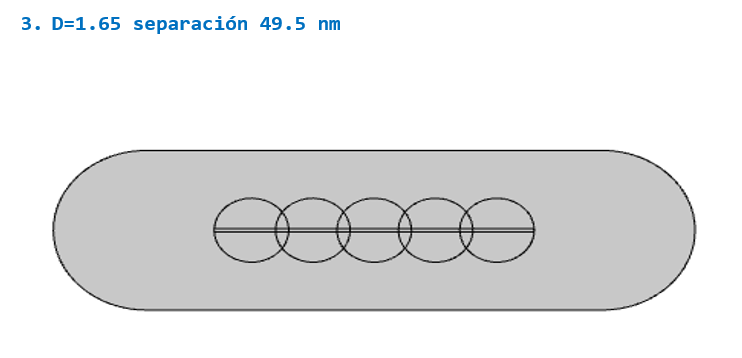

### E vs xi

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df3["X"]*1e9,df3["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs X')

plt.xlabel('Xi (nm)')
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df3o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] * 1e9
k = df_actual.columns[1:9]            # Selecciona las columnas, saltando X

plt.figure(figsize=(10, 6), dpi=150)
ax = plt.gca()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

colors = plt.cm.viridis(np.linspace(0.15, 0.95, len(k)))

for i, col in enumerate(k, start=1):
    ax.plot(
        xi_nm,
        df_actual[col],
        color=colors[i - 1],
        lw=2.8,
        alpha=0.95,
        solid_capstyle='round',
        label=f"$\\lambda$ = {i}"
    )

ax.set_ylim(-0.022, 0.005)
ax.set_xlim(-130, 130)
ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
ax.set_title("Energía vs Xi d=-10 ", fontsize=14, pad=20)
ax.grid(False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

ax.tick_params(axis='both', which='both', length=0, colors='#333333')

ax.legend(
    loc='center left',
    bbox_to_anchor=(1.01, 0.7),
    frameon=False,
    title='Valores propios',
    title_fontsize=10,
    fontsize=9,
    handlelength=2.0
)

plt.tight_layout()
plt.savefig('../figures/c_u_Evsxi_d-10.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df3o                     # Tu DataFrame
xi_nm = df_actual["X"] * 1e9
k = df_actual.columns[1:]            # Todas las columnas de valores propios

# ==========================================
# GRAFICA SEPARADA (Solo el primer valor)
# ==========================================
plt.figure(figsize=(10,6))

# Usamos k[0] para acceder exclusivamente a la primera columna
plt.plot(
    xi_nm,
    df_actual[k[0]],         # Dibujar solo la primera columna
    markersize=4,
    lw=3.5,
    label=f"Gráfica 1"
)

# Ajuste solicitado del eje Y
plt.ylim(-0.022, -0.020)

plt.xlabel("Xi (nm)")
plt.ylabel("Valor propio")
plt.title("Primer Valor Propio")
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Curvas"
)

plt.tight_layout()
plt.show()

### E vs F , xi=2d

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df3F["X"],df3F["Valor_propio"], s=1, alpha=0.5) # s es el tamaÃƒÆ’Ã‚Â±o del punto
plt.title('Energia vs F')
plt.xlabel('F (kV/cm)')
plt.ylabel('Energia (eV)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df3Fo                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(10,6))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5,
        label=f"Valor propio {i}"
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energgia (ev)")
plt.title("Energia vs F")
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Curvas"
)

plt.tight_layout()
plt.show()

### Analisi momento

In [ ]:
# ==========================================
# PARÁMETROS
# ==========================================
df_actual = df3Fo                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:3]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(10,6))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5,
        label=f"Valor propio {i}"
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energgia (ev)")
plt.title("Energia vs F")
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Curvas"
)

plt.tight_layout()
plt.show()

In [ ]:
# --- Análisis: ajuste de dos rectas para el primer valor propio (debajo de la celda 25)
# Define los límites a considerar: ajusta F_min y F_max según necesites
F_min, F_max = -2.0, 4.0
# Usamos el DataFrame con valores en función de F (df_actual) y la primera columna de valores propios
df = df_actual.copy()

F = np.array(df['X'])
col = df.columns[1]  # primer valor propio
E = np.array(df[col])
# Filtrar por los límites deseados
mask = (F >= F_min) & (F <= F_max)
Fm = F[mask]
Em = E[mask]
if len(Fm) < 3:
    print('No hay suficientes puntos en el rango seleccionado. Ajusta F_min/F_max')
else:
    # Detectar punto de quiebre local (máximo dentro del intervalo seleccionado)
    idx_local = np.argmax(Em)
    F_quiebre = Fm[idx_local]
    E_quiebre = Em[idx_local]

    # Función para calcular pendiente forzando la unión en (x0,y0)
    def pendiente_forzada(x, y, x0, y0):
        return np.sum((x - x0) * (y - y0)) / np.sum((x - x0)**2)

    # Separar en los dos tramos alrededor del punto de quiebre
    F1, E1 = Fm[:idx_local+1], Em[:idx_local+1]
    F2, E2 = Fm[idx_local:], Em[idx_local:]

    m1 = pendiente_forzada(F1, E1, F_quiebre, E_quiebre)
    m2 = pendiente_forzada(F2, E2, F_quiebre, E_quiebre)

    # Interceptos (forma y = m*x + b)
    b1 = E_quiebre - m1 * F_quiebre
    b2 = E_quiebre - m2 * F_quiebre

    # Imprimir resultados (pendientes y ecuaciones)
    print(f'Columna analizada: {col}')
    print(f'Recta 1: E = {m1:.6e} * F + {b1:.6e}    (pendiente = {m1:.6e})')
    print(f'Recta 2: E = {m2:.6e} * F + {b2:.6e}    (pendiente = {m2:.6e})')

    # Graficar: datos completos en gris, datos usados en naranja, y rectas ajustadas
    plt.figure(figsize=(10,6))
    plt.scatter(F, E, s=10, c='lightgray', label='Datos (completos)')
    plt.scatter(Fm, Em, s=30, c='orange', label='Datos usados')
    # Rectas ajustadas (se dibujan en el rango usado para cada tramo)
    plt.plot(F1, m1 * (F1 - F_quiebre) + E_quiebre, 'b-', lw=3, label=f'Tramo 1 (m={m1:.3e})')
    plt.plot(F2, m2 * (F2 - F_quiebre) + E_quiebre, 'r-', lw=3, label=f'Tramo 2 (m={m2:.3e})')
    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Energia (eV)')
    plt.title('Ajuste por dos rectas - primer valor propio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
# Celda 28: Graficar las pendientes (m1 y m2) vs F con la línea vertical de separación
try:
    # Asegurarse de que las variables m1, m2, F1, F2, F_quiebre estén definidas
    _ = (m1, m2, F1, F2, F_quiebre)
except Exception:
    print('Faltan variables necesarias (m1,m2,F1,F2,F_quiebre). Ejecuta la celda de análisis anterior.')
else:
    # Construir arrays de pendientes a lo largo de F para visualización
    # Usamos df_actual['X'] como eje F completo
    F_all = np.array(df_actual['X'])

    # Crear arrays de pendiente con NaN inicialmente
    pend1 = np.full_like(F_all, np.nan, dtype=float)
    pend2 = np.full_like(F_all, np.nan, dtype=float)

    # Rellenar pend1 en el rango de F1 y pend2 en el rango de F2
    # Para ello, identificamos índices en F_all que pertenecen a F1 y F2
    idx1 = np.isin(F_all, F1)
    idx2 = np.isin(F_all, F2)

    pend1[idx1] = m1
    pend2[idx2] = m2

    plt.figure(figsize=(10,6))
    plt.plot(F_all, pend1, 'b-', lw=3, label=f'Pendiente tramo 1 = {m1:.4e}')
    plt.plot(F_all, pend2, 'r-', lw=3, label=f'Pendiente tramo 2 = {m2:.4e}')

    # Línea vertical discontinua en el punto de quiebre
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')

    plt.xlabel('F (kV/cm)')
    plt.ylabel('Pendiente dE/dF (eV / (kV/cm))')
    plt.title('Pendientes por tramo vs F (primer valor propio)')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# CASO  NO UNIFORME 

## E vs R5  

### SIN IMPUREZA


In [ ]:
# ==========================================
# COMPARACIÓN CASOS SIN IMPUREZA: d=-10, d=0 y d=10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_R5sind_10o, "titulo": "d = -10 nm"},
    {"df": df_R5sind0o, "titulo": "d = 0 nm"},
    {"df": df_R5sind10o, "titulo": "d = 10 nm"},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Tomamos todas las columnas de valores propios (saltando 'X')
k_cols = df_R5sind0o.columns[1:]

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    F_val = df_actual["X"]
    
    # Graficar cada una de las curvas con los colores originales por defecto
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            F_val,
            df_actual[col],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"Valor propio {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de etiquetas de cada gráfica
    ax.set_xlabel(r"$\mathbf{F\ (kV/cm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía\ (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    
    # Habilitamos explícitamente los valores (ticks) del eje Y en todos los paneles
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)
    
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Energía vs R5 sin impureza", fontsize=15, weight='semibold', y=0.98)
plt.ylim(0,0.010)
plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/Evsr5.png', dpi=300, bbox_inches='tight')
plt.show()

### XI= 0


In [ ]:
# ==========================================
# COMPARACIÓN CASOS SIN IMPUREZA: d=-10, d=0 y d=10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_R5xi0d_10o, "titulo": "d = -10 nm"},
    {"df": df_R5xi0d0o, "titulo": "d = 0 nm"},
    {"df": df_R5xi0d10o, "titulo": "d = 10 nm"},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Tomamos todas las columnas de valores propios (saltando 'X')
k_cols = df_R5sind0o.columns[1:]

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    F_val = df_actual["X"]
    
    # Graficar cada una de las curvas con los colores originales por defecto
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            F_val,
            df_actual[col],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"Valor propio {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de etiquetas de cada gráfica
    ax.set_xlabel(r"$\mathbf{F\ (kV/cm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía\ (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    
    # Habilitamos explícitamente los valores (ticks) del eje Y en todos los paneles
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)

        
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)
# Título principal del panel completo
fig.suptitle("Energía vs R5 con impureza en xi=0", fontsize=15, weight='semibold', y=0.98)
plt.ylim(-0.022,0.011)
plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsR5xi_0.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:

#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xi0d0o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=0")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xi0d10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xi0d_10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=-10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

### Xi= R5


In [ ]:
# ==========================================
# COMPARACIÓN CASOS SIN IMPUREZA: d=-10, d=0 y d=10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_R5xiR5d_10o, "titulo": "d = -10 nm"},
    {"df": df_R5xiR5d0o, "titulo": "d = 0 nm"},
    {"df": df_R5xiR5d10o, "titulo": "d = 10 nm"},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Tomamos todas las columnas de valores propios (saltando 'X')
k_cols = df_R5sind0o.columns[1:]

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    F_val = df_actual["X"]
    
    # Graficar cada una de las curvas con los colores originales por defecto
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            F_val,
            df_actual[col],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"Valor propio {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de etiquetas de cada gráfica
    ax.set_xlabel(r"$\mathbf{F\ (kV/cm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía\ (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    
    # Habilitamos explícitamente los valores (ticks) del eje Y en todos los paneles
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)

        
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Energia vs R5 con impureza en xi=R5", fontsize=15, weight='semibold', y=0.98)

plt.ylim(-0.022,0.009)
plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsR5xi_R5.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR5d0o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=0")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR5d10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR5d_10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=-10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

### Xi= R1


In [ ]:
# ==========================================
# COMPARACIÓN CASOS SIN IMPUREZA: d=-10, d=0 y d=10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_R5xiR1d_10o, "titulo": "d = -10 nm"},
    {"df": df_R5xiR1d0o, "titulo": "d = 0 nm"},
    {"df": df_R5xiR1d10o, "titulo": "d = 10 nm"},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Tomamos todas las columnas de valores propios (saltando 'X')
k_cols = df_R5sind0o.columns[1:]

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    F_val = df_actual["X"]
    
    # Graficar cada una de las curvas con los colores originales por defecto
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            F_val,
            df_actual[col],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"Valor propio {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de etiquetas de cada gráfica
    ax.set_xlabel(r"$\mathbf{F\ (kV/cm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía\ (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    
    # Habilitamos explícitamente los valores (ticks) del eje Y en todos los paneles
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)

        
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Comparativa de Energía vs F (Sin Impureza)", fontsize=15, weight='semibold', y=0.98)

plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsR1xi_0.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR1d0o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=0")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR1d10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

In [ ]:
#d=0
# PARÁMETROS
# ==========================================
df_actual = df_R5xiR1d_10o                     # Aquí pones el DataFrame que quieras usar
xi_nm = df_actual["X"] 
k = df_actual.columns[1:]            # Selecciona las columnas, saltando 'X'

# ==========================================
# GRAFICA SEPARADA
# ==========================================
plt.figure(figsize=(5,5))

for i, col in enumerate(k, start=1):   # Itera sobre la variable k
    plt.plot(
        xi_nm,
        df_actual[col],         # Dibujar puntos
        markersize=4,
        lw=3.5
    )

plt.xlabel("F (kV/cm)")
plt.ylabel("Energia (eV)")
plt.title("d=-10")
plt.grid(False)

# Leyenda oculta como se solicitó

plt.tight_layout()
plt.show()

### 

## Energia vs impureza

In [ ]:
# ==========================================
# COMPARACIÓN CASOS UNIFORMES: d=0, d=10 y d=-10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_xiR5_50d_10o, "titulo": "d = -10 nm", "xlim": (-130, 130), "ylim": (-0.022, 0.005)},
    {"df": df_xiR5_50d0o, "titulo": "d = 0 nm", "xlim": (-150, 150), "ylim": (-0.022, 0.005)},
    {"df": df_xiR5_50d10o, "titulo": "d = 10 nm", "xlim": (-180, 180), "ylim": (-0.022, 0.005)},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Número de curvas (lambda)
n_col = df1o.shape[1] - 1  # restamos la columna 'X'
k_cols = df1o.columns[1:] # tomamos hasta las primeras 8 curvas

# Usamos la misma paleta cividis que en la celda 13
colors = plt.cm.cividis(np.linspace(0.15, 0.95, len(k_cols)))

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    xi_nm = df_actual["X"] * 1e9
    
    # Graficar cada una de las curvas
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            xi_nm,
            df_actual[col],
            color=colors[i - 1],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"$\\lambda$ = {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de límites y etiquetas de cada gráfica
    ax.set_xlim(caso["xlim"])
    ax.set_ylim(caso["ylim"])
    ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)
    
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Energia vs xi R5=50 nm", fontsize=15, weight='semibold', y=0.98)

plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsxiR5_50.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ==========================================
# COMPARACIÓN CASOS UNIFORMES: d=0, d=10 y d=-10 nm
# ==========================================

# Definición de los DataFrames y títulos correspondientes
casos = [
    {"df": df_xiR5_10d_10o, "titulo": "d = -10 nm", "xlim": (-130, 130), "ylim": (-0.022, 0.005)},
    {"df": df_xiR5_10d0o, "titulo": "d = 0 nm", "xlim": (-150, 150), "ylim": (-0.022, 0.005)},
    {"df": df_xiR5_10d10o, "titulo": "d = 10 nm", "xlim": (-180, 180), "ylim": (-0.022, 0.005)},
]

# Configuración de tipografías globales de matplotlib
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.labelweight": "normal"
})

# Creamos un panel con 1 fila y 3 columnas compartiendo el eje Y
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150, sharey=True)

# Número de curvas (lambda)
n_col = df1o.shape[1] - 1  # restamos la columna 'X'
k_cols = df1o.columns[1:9] # tomamos hasta las primeras 8 curvas

# Usamos la misma paleta cividis que en la celda 13
colors = plt.cm.cividis(np.linspace(0.15, 0.95, len(k_cols)))

for idx, caso in enumerate(casos):
    ax = axs[idx]
    df_actual = caso["df"]
    xi_nm = df_actual["X"] * 1e9
    
    # Graficar cada una de las curvas
    for i, col in enumerate(k_cols, start=1):
        ax.plot(
            xi_nm,
            df_actual[col],
            color=colors[i - 1],
            lw=2.8,
            alpha=0.95,
            solid_capstyle='round',
            label=f"$\\lambda$ = {i}" if idx == 2 else "" # Ponemos la leyenda solo en el último subplot para evitar duplicados
        )
    
    # Configuración de límites y etiquetas de cada gráfica
    ax.set_xlim(caso["xlim"])
    ax.set_ylim(caso["ylim"])
    ax.set_xlabel(r"$\mathbf{Xi (nm)}$", fontsize=11)
    if idx == 0:
        ax.set_ylabel(r"$\mathbf{Energía (eV)}$", fontsize=11)
        
    ax.set_title(caso["titulo"], fontsize=13, pad=15)
    ax.grid(False)
    
    # Estética minimalista (eliminar bordes superior/derecho y ajustar grosores)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    ax.tick_params(axis='both', which='both', length=0, colors='#333333', labelleft=True)
    
    # --- ANOTACIÓN DEL VALOR MÍNIMO EN EL EJE Y (TEXTO NEGRO NEGRITA, SIN RECUADRO) ---
    minimo_global = float('inf')
    for col in k_cols:
        min_curva = df_actual[col].min()
        if min_curva < minimo_global:
            minimo_global = min_curva
    
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax.text(
        xlims[0], ylims[0] - (ylims[1] - ylims[0]) * 0.04,
        f"Mín: {minimo_global:.5f}",
        fontsize=8,
        color='#333333',
        fontweight='bold',
        ha='left',
        va='top'
    )

# Añadir una leyenda unificada a la derecha del todo
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    title='Valores propios',
    title_fontsize=11,
    fontsize=9,
    handlelength=2.0
)

# Título principal del panel completo
fig.suptitle("Energia vs xi R5=10 nm", fontsize=15, weight='semibold', y=0.98)

plt.tight_layout()
# Ajustar espacio para la leyenda a la derecha y el título arriba
plt.subplots_adjust(right=0.90, top=0.88, wspace=0.15)

# Guardar la gráfica en la carpeta de exportadas
plt.savefig('../figures/EvsxiR5_10.png', dpi=300, bbox_inches='tight')
plt.show()

# Analisis momento dipolar es AQUI DEEPSEK 

In [ ]:
def analisis_momento_dipolar(df, F_min=-1.1, F_max=2):
    """Analisis del momento dipolar: imprime las 3 graficas (curvas ordenadas,
    ajuste de dos rectas y pendientes por tramo) para el DataFrame dado.

    Parametros
    ----------
    df : DataFrame ya organizado (ej. df_AEvsF_R10_d_0o)
    F_min, F_max : limites del intervalo de F para el ajuste (default -1.1, 2)
    """
    df_actual = df.copy()

    # ==========================================
    # GRAFICA 1: Curvas ordenadas de todos los valores propios vs F
    # ==========================================
    xi_nm = df_actual['X']
    k = df_actual.columns[1:]            # columnas de valores propios (salta 'X')

    plt.figure(figsize=(10, 6))
    for i, col in enumerate(k, start=1):
        plt.plot(xi_nm, df_actual[col], markersize=4, lw=3.5, label=f'Valor propio {i}')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Energia (eV)')
    plt.title('Energia vs F')
    plt.grid(True, alpha=0.3)
    plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), title='Curvas')
    plt.tight_layout()
    plt.show()

    # ==========================================
    # GRAFICA 2: Ajuste de dos rectas (primer valor propio) + punto de quiebre
    # ==========================================
    F = np.array(df_actual['X'])
    col = df_actual.columns[1]           # primer valor propio
    E = np.array(df_actual[col])
    mask = (F >= F_min) & (F <= F_max)
    Fm, Em = F[mask], E[mask]

    if len(Fm) < 3:
        print('No hay suficientes puntos en el rango seleccionado. Ajusta F_min/F_max')
        return

    idx_local = np.argmax(Em)
    F_quiebre = Fm[idx_local]
    E_quiebre = Em[idx_local]

    def pendiente_forzada(x, y, x0, y0):
        return np.sum((x - x0) * (y - y0)) / np.sum((x - x0)**2)

    F1, E1 = Fm[:idx_local+1], Em[:idx_local+1]
    F2, E2 = Fm[idx_local:], Em[idx_local:]

    m1 = pendiente_forzada(F1, E1, F_quiebre, E_quiebre)
    m2 = pendiente_forzada(F2, E2, F_quiebre, E_quiebre)

    b1 = E_quiebre - m1 * F_quiebre
    b2 = E_quiebre - m2 * F_quiebre

    print(f'Columna analizada: {col}')
    print(f'Recta 1: E = {m1:.6e} * F + {b1:.6e}    (pendiente = {m1:.6e})')
    print(f'Recta 2: E = {m2:.6e} * F + {b2:.6e}    (pendiente = {m2:.6e})')

    plt.figure(figsize=(10, 6))
    plt.scatter(F, E, s=10, c='lightgray', label='Datos (completos)')
    plt.scatter(Fm, Em, s=30, c='orange', label='Datos usados')
    plt.plot(F1, m1 * (F1 - F_quiebre) + E_quiebre, 'b-', lw=3, label=f'Tramo 1 (m={m1:.3e})')
    plt.plot(F2, m2 * (F2 - F_quiebre) + E_quiebre, 'r-', lw=3, label=f'Tramo 2 (m={m2:.3e})')
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Energia (eV)')
    plt.title('Ajuste por dos rectas - primer valor propio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ==========================================
    # GRAFICA 3: Pendientes por tramo (m1, m2) vs F + linea de quiebre
    # ==========================================
    F_all = np.array(df_actual['X'])
    pend1 = np.full_like(F_all, np.nan, dtype=float)
    pend2 = np.full_like(F_all, np.nan, dtype=float)
    idx1 = np.isin(F_all, F1)
    idx2 = np.isin(F_all, F2)
    pend1[idx1] = m1
    pend2[idx2] = m2

    plt.figure(figsize=(10, 6))
    plt.plot(F_all, pend1, 'b-', lw=3, label=f'Pendiente tramo 1 = {m1:.4e}')
    plt.plot(F_all, pend2, 'r-', lw=3, label=f'Pendiente tramo 2 = {m2:.4e}')
    plt.axvline(F_quiebre, color='k', linestyle='--', lw=1.5, label=f'Punto de quiebre (F={F_quiebre:.3f})')
    plt.xlabel('F (kV/cm)')
    plt.ylabel('Pendiente dE/dF (eV / (kV/cm))')
    plt.title('Pendientes por tramo vs F (primer valor propio)')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


 ### Grafica # R=10 d=0


In [ ]:
aux=df_AEvsF_R10_d_0

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R10_d_0o)

### Grafica # R=10 d=10


In [ ]:

aux=df_AEvsF_R10_d_10

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R10_d_10o)


### Grafica # R=10 d=-10


In [ ]:

aux=df_AEvsF_R10_d_menos10

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R10_d_menos10o)


### Grafica # R=50 d=0


In [ ]:

aux=df_AEvsF_R50_d_0

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R50_d_0o)


### Grafica # R=50 d=10


In [ ]:

aux=df_AEvsF_R50_d_10

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R50_d_10o)


### Grafica # R=50 d=-10


In [ ]:

aux=df_AEvsF_R50_d_menos10

plt.figure(figsize=(10, 6))
plt.scatter(aux["X"], aux["Valor_propio"], s=1, alpha=0.5) # s es el tamaño del punto
plt.title('Energia vs F')
plt.xlabel("F (kV/cm)")
plt.ylabel('Energia (ev)')
plt.grid(True)
plt.show()

In [ ]:
analisis_momento_dipolar(df_AEvsF_R50_d_menos10o)


In [ ]:
# ==========================================
# TABLA COMPARATIVA DEL MOMENTO DIPOLAR (m1, m2, F_quiebre)
# ==========================================
def _ajuste_quiebre(df, F_min=-1.1, F_max=2):
    """Devuelve (F_quiebre, m1, m2) para el primer valor propio."""
    F = np.array(df['X'])
    E = np.array(df[df.columns[1]])
    mask = (F >= F_min) & (F <= F_max)
    Fm, Em = F[mask], E[mask]
    if len(Fm) < 3:
        return np.nan, np.nan, np.nan
    i = np.argmax(Em)
    Fq, Eq = Fm[i], Em[i]
    def pend(x, y, x0, y0):
        return np.sum((x - x0) * (y - y0)) / np.sum((x - x0)**2)
    m1 = pend(Fm[:i+1], Em[:i+1], Fq, Eq)
    m2 = pend(Fm[i:], Em[i:], Fq, Eq)
    return Fq, m1, m2

casos_tabla = [
    ('R=10 d=0',   'df_AEvsF_R10_d_0o'),
    ('R=10 d=10',  'df_AEvsF_R10_d_10o'),
    ('R=10 d=-10', 'df_AEvsF_R10_d_menos10o'),
    ('R=50 d=0',   'df_AEvsF_R50_d_0o'),
    ('R=50 d=10',  'df_AEvsF_R50_d_10o'),
    ('R=50 d=-10', 'df_AEvsF_R50_d_menos10o'),
]

filas = []
for caso, var in casos_tabla:
    dfc = globals().get(var)
    if dfc is None:
        filas.append({'Caso': caso, 'F_quiebre (kV/cm)': np.nan, 'm1': np.nan, 'm2': np.nan})
        continue
    Fq, m1, m2 = _ajuste_quiebre(dfc)
    filas.append({'Caso': caso, 'F_quiebre (kV/cm)': Fq, 'm1': m1, 'm2': m2})

tabla_df = pd.DataFrame(filas)
print('Comparacion del momento dipolar (primer valor propio):')
print(tabla_df.to_string(index=False))


### 1. Caso Uniforme 

| Configuración | Pendiente Tramo 1 ($m_1$) | Pendiente Tramo 2 ($m_2$) | Punto de Quiebre ($F$) [kV/cm] |
| :--- | :--- | :--- | :--- |
| **$d = -10$ nm** | 0.0098998 | -0.010306 | 1.200 |
| **$d = 0$ nm** | 0.012002 | -0.012426 | 1.000 |
| **$d = 10$ nm** | 0.014999 | -0.014689 | 0.800 |

<br>

### 2. Caso Asimétrico 

| Configuración | Pendiente Tramo 1 ($m_1$) | Pendiente Tramo 2 ($m_2$) | Punto de Quiebre ($F$) [kV/cm] |
| :--- | :--- | :--- | :--- |
| **$R = 10, d = 0$ nm** | 0.009984 | -0.011757 | 0.90 |
| **$R = 10, d = 10$ nm** | 0.011553 | -0.014501 | 0.80 |
| **$R = 10, d = -10$ nm** | 0.007908 | -0.010522 | 1.20 |
| **$R = 50, d = 0$ nm** | 0.013535 | -0.012533 | 0.95 |
| **$R = 50, d = 10$ nm** | 0.015301 | -0.014278 | 0.80 |
| **$R = 50, d = -10$ nm** | 0.011759 | -0.010498 | 1.10 |